In [2]:
import sys
print(sys.version)
# been running on 3.11.9 pyenv
# if it prints something like 3.15,
# switch the notebook kernel to a Python 3.10/3.11 environment and rerun the install!

3.11.9 (main, Oct 25 2026, 17:00:07) [Clang 15.0.0 (clang-1500.3.9.4)]


In [3]:
# had to add this primary install after deciding to connect to a local jupyter runtime
# !pip install -q torch torchaudio librosa

!pip install -r requirements.txt

import os
import shutil
from pathlib import Path

# force reinstall matched, stable versions of torch and torchaudio
# !pip install --force-reinstall torch torchaudio --index-url https://download.pytorch.org/whl/cpu

from sklearn.model_selection import train_test_split  # using for targeted data augmentation now
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import Subset # added also for data augmentation
from torch.utils.tensorboard import SummaryWriter
!pip install tensorboard
import matplotlib.pyplot as plt
import librosa
import librosa.display
import pandas as pd
import IPython
from IPython.display import Audio, display
import numpy as np
import random
import copy
import json   # 11.17 for the Scaper render settings stamp
import soundfile as sf
!pip install scaper
np.Inf = np.inf  # scaper 1.6.5 still uses np.Inf, which NumPy 2.0 removed
import scaper
from datetime import datetime

# 11.17 SEEDING -- one seed for everything, so the CNN and the spec AE see the same augmented data
# (speaker split already uses np.random.default_rng(42); Scaper renders, live noise, shuffling and weight init now follow SEED too)
SEED = 42
def seed_everything(seed=SEED):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
seed_everything()

### torchaudio.io and thus StreamReader would not import... tried upgrading torch version, etc.
# !add-apt-repository -y ppa:savoury1/ffmpeg4
# !apt-get -qq install -y ffmpeg
# from torchaudio.io import StreamReader

# I'm sure there are more efficient uses of some of these packages such that I would not need any overlap


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [4]:
# installing Kaggle API client
!pip install -q kaggle

# moving the kaggle.json into a new folder
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle

# 11.10 check for files before needlessly redownloading
DATA_DIR = Path.cwd() / "data"

# filenames expected = digit 0-9 x speaker 01-60 x take 0-49 = 30,000 names like "3_07_12.wav"
EXPECTED = {f"{d}_{s:02d}_{k}.wav" for d in range(10) for s in range(1, 61) for k in range(50)}

# look ANYWHERE under data/ so that this works whether files are still in the speaker subfolders or already in audio_files
found_paths = list(DATA_DIR.rglob("*.wav")) if DATA_DIR.exists() else []
found = {p.name for p in found_paths}       # a set, so duplicates (same name in two folders) count once
missing = EXPECTED - found
empty = sum(1 for p in found_paths if p.stat().st_size == 0)    # 0-byte files exist but are unusable

have_dataset = len(missing) == 0
print(f"found {len(found)} / {len(EXPECTED)} expected .wav files | missing {len(missing)} | empty (0 bytes) {empty}")

if have_dataset:
  print("Full dataset already on disk -- skipping the Kaggle download.")
else:
  print("Dataset incomplete -- downloading.")
  !kaggle datasets download -d sripaadsrinivasan/audio-mnist
  !unzip audio-mnist.zip

# examine metadata .txt file (to work with different attributes)
# with open("/content/data/audioMNIST_meta.txt", "r", encoding="utf-8") as file:
#   for line in file:
#     print(line.strip())


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
cp: kaggle.json: No such file or directory
found 30000 / 30000 expected .wav files | missing 0 | empty (0 bytes) 0
Full dataset already on disk -- skipping the Kaggle download.


In [5]:
# Datasets: AudioMNIST (clean), augmentation now happens later inside 'CachedDataset'
# removing subfolders just so it's easier for *me to parse for now.

project_root = Path("/Users/madelinemccormack/Desktop/PhD/PersonalResearch/AudioMNIST_CNN")
base_search_dir = Path.cwd() / "data"
target_dir = base_search_dir / "audio_files"
target_dir.mkdir(parents=True, exist_ok=True)

# find all .wav files in /content/data and move them to audio_files
for path in base_search_dir.rglob("*.wav"):
  if path.stat().st_size == 0:
     continue
  
  if path.parent != target_dir:
    try:
        shutil.move(str(path), str(target_dir / path.name))
    except Exception:
        pass

class AudioMNISTDataset(Dataset):
  def __init__(self, root_dir, target_sr=8000, num_samples=8000):
    self.target_sr = target_sr
    self.num_samples = num_samples
    self.root_dir = Path(root_dir)

    # retrieve all files -- CHANGED: now keeping all 60 speakers (used to filter to speakers 01 thru 10)
    all_files = sorted(self.root_dir.glob("*.wav"))  # sorted so file order (and so the split) is the same every run
    self.file_paths = []
    for path in all_files:
        try:
            # filename format is {digit}_{speaker}_{index}.wav (e.g., '0_01_0.wav')
            parts = path.name.split('_')
            if len(parts) >= 2:
                int(parts[0]), int(parts[1])  # check digit and speaker are numbers
                self.file_paths.append(path)
        except (ValueError, IndexError):
            # skip files that don't match the expected naming format
            pass

  def __len__(self):
    return len(self.file_paths)

  def __getitem__(self, idx):
    path = self.file_paths[idx]
    waveform, sr = torchaudio.load(str(path))

    # flag for empty wav files!
    if waveform.numel() == 0:
       raise ValueError(f"empty waveform found at {path}")

    # extract digit label from filename
    digit = int(path.name.split('_')[0])

    if sr != self.target_sr:
      waveform = torchaudio.functional.resample(waveform, sr, self.target_sr)

    n = waveform.shape[1]
    if n < self.num_samples:
      waveform = F.pad(waveform, (0, self.num_samples - n))
    else:
      waveform = waveform[:, :self.num_samples]

    x = waveform.squeeze(0)
    return x, digit

full_ds = AudioMNISTDataset(root_dir=str(target_dir))
print(f"Total samples found: {len(full_ds)}")

# CHANGED: split by SPEAKER instead of by file, so no voice shows up in more than one split
# (the file-level split put the same 10 speakers in train, val AND test -> val/test accuracy only measured voices it had already heard)
# no stratify needed -- every speaker recorded every digit 50 times, so digits stay balanced on their own
speakers = np.array([int(p.name.split('_')[1]) for p in full_ds.file_paths])  # speaker of every file, from the filename only

# hold out whole speakers: 48 train / 6 val / 6 test
spk_order = np.random.default_rng(42).permutation(np.unique(speakers))
val_spk, test_spk = spk_order[:6], spk_order[6:12]
print("val speakers:", sorted(val_spk.tolist()), "| test speakers:", sorted(test_spk.tolist()))

train_idx = np.where(~np.isin(speakers, np.concatenate([val_spk, test_spk])))[0]
val_idx = np.where(np.isin(speakers, val_spk))[0]
test_idx = np.where(np.isin(speakers, test_spk))[0]

###
# REMOVED AugmentedDataset class!! Now will be augmenting inside the dataset and then caching it
# froze one random augmentation per clip. So augmentation now lives in NEW CachedDataset in the next cell,
# so it re-rolls every epoch
###

# CHANGED from augmented and validation dataset splits to -> plain/clean subsets of the dataset (again, no augmentation at this stage)
train_dataset = Subset(full_ds, train_idx)
val_dataset = Subset(full_ds, val_idx)
test_dataset = Subset(full_ds, test_idx)  # CHANGED - own held-out speakers now, instead of a random_split of val

print(f" train size: {len(train_dataset)}") # changed from aug
print(f" test size: {len(test_dataset)}")
print(f" val size: {len(val_dataset)}")

loader = DataLoader(train_dataset, batch_size=5, shuffle=True)  # again, changed from aug
for x, y in loader:
  print("Batch shape:", x.shape, "Labels:", y)
  break

Total samples found: 30000
val speakers: [8, 18, 19, 25, 29, 56] | test speakers: [6, 28, 40, 45, 51, 60]
 train size: 24000
 test size: 3000
 val size: 3000
Batch shape: torch.Size([5, 8000]) Labels: tensor([8, 0, 5, 3, 4])


File selected: /Users/madelinemccormack/Documents/GitHub/Spec_AudioMNIST_Autoencoder/data/audio_files/5_38_28.wav


/Users/madelinemccormack/.pyenv/versions/3.11.9/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


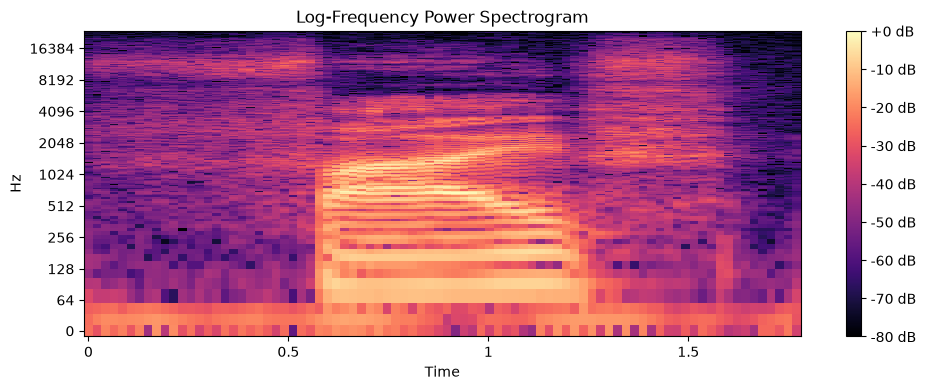

In [6]:
# visualize a .wav sample's spectrogram, selected randomly from just the first speaker in the dataset -- this was just nice to look at, and keep in mind

def get_random_file(folder_path):
    dir_path = Path(folder_path)

    # ignores subfolders
    files = [file for file in dir_path.iterdir() if file.is_file()]

    if not files:
        return None  # if folder is empty or only contains subdirectories

    # return a randomly selected file path
    random_file = random.choice(files)
    print(f"File selected: {random_file}")
    return random_file

def plot_spectrogram(file_path):
    # load audio file (librosa automatically handles resampling)
    y, sr = librosa.load(file_path, sr=None)

    # computing the Short-Time Fourier Transform (STFT)
    stft_matrix = librosa.stft(y)

    # converting amplitude to decibels (log scale)
    stft_db = librosa.amplitude_to_db(np.abs(stft_matrix), ref=np.max)

    # plot the spectrogram
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(stft_db, sr=sr, x_axis='time', y_axis='log', hop_length=1024, bins_per_octave=24, cmap='magma')

    plt.colorbar(format='%+2.0f dB')
    plt.title('Log-Frequency Power Spectrogram')
    plt.tight_layout()
    plt.show()

file_path = get_random_file(str(target_dir))
plot_spectrogram(file_path)

In [7]:
# SCAPER
# because it writes files to disk, can't run per sample inside CachedDataset.__getitem__ every epoch sadly
# so here, generates noisy copies of training clips (mix each digit over background noise at a controlled SNR)
# might next just consolidate - remove the speed perturbation method and utilize Scaper for its pitch and time-stretch options

# 11.17 SEEDED + REUSED: each render now gets its own random_state, and renders are only generated ONCE!!
# scaper_out is kept between runs as long as its settings stamp (seed, limits, ranges, exact train file list) still matches
# -> both networks (and reruns) train on the identical pitch/stretch copies
# only the soundbank is rebuilt every run (cheap + deterministic: symlinks and seeded synthetic noise)
SCAPER_SEED = SEED  # from the imports cell
FORCE_REGEN = False   # True = throw away scaper_out and re-render anyway
SCAPER_OUT = Path("scaper_out")   # to share ONE render with the CNN project, can just point both notebooks at the same absolute path
SCAPER_JAMS = Path("scaper_jams")
PS_RANGE = (-2, 2)  # pitch shift, semitones
TS_RANGE = (0.85, 1.15) # time stretch factor

if Path("scaper_bank").exists():
  shutil.rmtree("scaper_bank")

LIMIT = 9600   # set to 9600 (40% of 24000 train clips)
PS_EVERY = 4   # 11.10 one variant per 4th train clip (approx 6,000 clips instead of 24,000, to keep rendering time down)
SC_DURATION = 1.0  # soundscape length. Longer than 1 s so stretching has room; the dataset trims to 1 s later

# Scaper requires soundbank of "foreground" and "background" folders, each w/ subfolders named after the label of the sounds inside
bank = Path("scaper_bank")
fg_root, bg_root = bank / "foreground", bank / "background"
out_dir, jams_dir = SCAPER_OUT, SCAPER_JAMS
# clear the foreground shortcuts and noisy copies from any earlier run first --
# if the split changed, leftovers from speakers now in val/test would leak back into training
# for d in [fg_root, out_dir, jams_dir]:
#   if d.exists():
#     shutil.rmtree(d)
for d in [fg_root, bg_root / "noise", out_dir, jams_dir]:
  d.mkdir(parents=True, exist_ok=True)
for digit in range(10):
  (fg_root / str(digit)).mkdir(exist_ok=True) # one foreground subfolder per digit!

# foreground soundbank - the TRAIN files only (never val/test, or near-copies would leak into training)
train_files = [full_ds.file_paths[i] for i in train_idx]  # turn train split's index numbers into file paths
for p in train_files:
  link = fg_root / p.name.split('_')[0] / p.name
  if not link.exists():
    link.symlink_to(p.resolve())  # make shortcut to original file instead of copying it (saves disk space)

# 11.10 NOISE soundbank - 2 synthetic noises, saved as wav in the folder AddBackground reads live during training
# (I could switch to dropping in real noise recordings into this same folder for more realism...)
rng = np.random.default_rng(0)
white = rng.standard_normal(10 * 48000)
brown = np.cumsum(white)
brown -= np.convolve(brown, np.ones(4800) / 4800, mode="same")
for name, sig in [("white", white), ("brown", brown)]:
  sf.write(str(bg_root / "noise" / f"{name}.wav"), 0.1 * sig / np.abs(sig).max(), 48000)

# background soundbank - two synthetic noises (I could swap in real noise recordings for more realism, but just generating simple white and brown here)
rng = np.random.default_rng(0)  # using random number generator w/ a fixed seed for same noise every run
white = rng.standard_normal(10 * 48000) # 10s of random numbers at 48 kHz
brown = np.cumsum(white)  # nifty brown noise - adding random numbers up
brown -= np.convolve(brown, np.ones(4800) / 4800, mode="same")   # subtract a slow moving average (0.1 sec window) to remove the long, slow drift
for name, sig in [("white", white), ("brown", brown)]:
  # scaling each noise so its loudest point is 0.1 (quiet, no clipping) and save in the 'noise' background folder
  sf.write(str(bg_root / "noise" / f"{name}.wav"), 0.1 * sig / np.abs(sig).max(), 48000)

# torchaudio already started SoX - starting it a second time here crashed the kernel
# so shutting torchaudio's down first (torchaudio.load still works after this)
torch.ops.torchaudio_sox.shutdown_sox_effects()

# 11.10 render pitch-shifted / time-stretched variants of train clips (NO noise here!! noise added live later)
# generating one ps copy per train clip here
render_files = train_files[:LIMIT] if LIMIT else train_files[::PS_EVERY]  # 11.10 subsample when LIMIT is None

# 11.17 reuse check: settings stamp must match AND every expected render must exist
stamp = {"seed": SCAPER_SEED, "limit": LIMIT, "ps_every": PS_EVERY, "duration": SC_DURATION,
         "pitch_shift": list(PS_RANGE), "time_stretch": list(TS_RANGE), "files": [p.name for p in render_files]}
stamp_path = out_dir / "_render_settings.json"   # .json, so AudioMNISTDataset's *.wav glob ignores it
up_to_date = (not FORCE_REGEN and stamp_path.exists() and json.loads(stamp_path.read_text()) == stamp
              and all((out_dir / f"{p.stem}_ps.wav").exists() for p in render_files))
if up_to_date:
  print(f"reusing {len(render_files)} seeded renders in {out_dir.resolve()} (set FORCE_REGEN = True to redo)")
  todo = []
else:
  print("no matching seeded renders found -- rendering (one time)")
  for d in [out_dir, jams_dir]:   # clear old unseeded / mismatched renders, so nothing stale gets mixed in
    shutil.rmtree(d)
    d.mkdir(parents=True)
  todo = render_files

n_ok, n_fail = 0, 0   # counters, so that we can report how many worked and how many failed
for k, p in enumerate(todo):
  digit = p.name.split('_')[0]
  link = fg_root / digit / p.name   # clip's shortcut inside soundbank
  dur = sf.info(str(p)).duration - 0.01    # 11.10 the WHOLE digit (mistake of mine to try 75% of it, which could chop the end)
  try:
    sc = scaper.Scaper(SC_DURATION, str(fg_root), str(bg_root),   # start a new and empty 1 second soundscape that knows where the soundbank is
                       random_state=SCAPER_SEED + k)  # 11.17 per-clip seed -> the same clip always gets the same pitch/stretch
    sc.ref_db = -20   # 11.10 WAS -50dB, too quiet. loudness of background noise; digit's loudness is set relative to this via snr below
    # 11.10 NO MORE add_background here. Noise is mixed in live by AddBackground
    # sc.add_background(label=('const', 'noise'), source_file=('choose', []),
    #                   source_time=('uniform', 0, 9))    # start reading the noise at a random point (0-9 sec into the 10-sec file) so a full 1 sec is always available
    sc.add_event(label=('const', digit), source_file=('const', str(link)),    # this event is digit being worked on
                 source_time=('const', 0), event_time=('const', 0),   # start reading clip from its start
                 event_duration=('const', dur),     # place it at start of soundscape
                 snr=('const', 0),                   # dB vs background. 11.10 no background to compare to; cache_split peak-normalizes anyway
                 pitch_shift=('uniform', *PS_RANGE),    # 11.10 units in semitones
                 time_stretch=('uniform', *TS_RANGE))  # INDEPENDENT of pitch
    stem = p.stem + "_ps"                               # 11.10 eg '3_07_12_ps.wav'
    sc.generate(str(out_dir / f"{stem}.wav"), str(jams_dir / f"{stem}.jams"),   # mix and save, plus a helpful .jams file that records exactly what was mixed in
                allow_repeated_label=True, allow_repeated_source=True,    # these two just let the same digit/file be reused w/o Scaper complaining
                disable_sox_warnings=True)    # hide annoying audio-tool warnings
    n_ok += 1
  except Exception as e:
    n_fail += 1
    if n_fail == 1: print("first failure:", repr(e))    # show only a first error message, so a repeated problem doesn't overwhelm my screen
if todo:
  print(f"generated {n_ok}, failed {n_fail}")
  if n_fail == 0:
    stamp_path.write_text(json.dumps(stamp))   # only stamp a COMPLETE render, so a partial one gets redone next run

# listen back to one generated clip
made = sorted(out_dir.glob("*_ps.wav"), key=lambda f: f.stat().st_mtime)   # all generated clips (oldest first, newest last)
if made:
  LISTEN = -1   # -1 = newest clip, change to hear others
  ps_path = made[LISTEN]
  data, sr = sf.read(str(ps_path))
  if data.ndim > 1:
    data = data.mean(axis=1)    # if it came out stereo, average to mono so the player accepts it
  print("pitch/stretch variant:", ps_path.name)
  display(Audio(data, rate=sr))

  # original clean clip for comparison (shortcut in the soundbank points to original file)
  clean_path = fg_root / ps_path.name.split('_')[0] / ps_path.name.replace("_ps", "")
  # skip politely if the shortcut is missing or broken
  if clean_path.exists():
    clean, csr = sf.read(str(clean_path))
    print("clean:", clean_path.name)
    display(Audio(clean, rate=csr))
  else:
    print("original not found at", clean_path)
else:
  print("no clips were generated - check the 'first failure' message above")

# Note though - the noise is frozen... each clip gets one fixed noisy copy, so it doesn’t re-roll every epoch the way CachedDataset does
# having both clean and noisy copies, plus the speed perturbation on top, kind of softens this?
# I could also maybe do something like loop twice with different file suffixes for two noisy copies
# Scaper feels clearly heavy to do for just noise mixing, but again, the idea is to expand its usage / get familiar

reusing 9600 seeded renders in /Users/madelinemccormack/Documents/GitHub/Spec_AudioMNIST_Autoencoder/scaper_out (set FORCE_REGEN = True to redo)
pitch/stretch variant: 3_59_9_ps.wav


clean: 3_59_9.wav


In [8]:
# DATASET SPLITS, DATALOADERS

# 11.10 Timestamping and sorting TensorBoard runs
# generating one timestamp at start of the training cell, then building both TensorBoard folders from it
# each run gets its own timestamped folder (and the two writers share the same stamp)
RUN_ID = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")          # 24hr format: 2026-11-10_19-20-05
RUN_NOTE = ""                                                  # *optional tag, e.g. "inputBN" or "scaper"
if RUN_NOTE:
  RUN_ID += f"_{RUN_NOTE}"
print("run id:", RUN_ID)

# running locally in VS Code here, so setting device to MAC GPU
if torch.backends.mps.is_available():
  device = torch.device("mps")
  print("Mac GPU (MPS) is available")
else:
  device = torch.device("cpu")
  print("MPS not available. Falling back to CPU")

# cache each split as tensors -- so the audio is loaded/resampled once -- not every epoch!
# I needed the most help with this, wasn't familiar with the method itself
# MINOR CHANGE: that bad-clip skipping/check now occurs in here (more appropriate)
def cache_split(subset):
  xs, ys, bad = [], [], []
  for i in range(len(subset)):
    try:
      x, y = subset[i]
    except ValueError:  # now raise simple ValueError on empty WAVs (no str 'bad sample count' though)
      bad.append(i)
      continue
    x = x / x.abs().max().clamp(min=1e-8) # peak normalization
    xs.append(x)
    ys.append(y)
  return torch.stack(xs).unsqueeze(1), torch.tensor(ys) # [N, 1, 8000]

# implement cache_split()
# NOW all three splits are cached clean
Xtr, ytr = cache_split(train_dataset)  # this takes a moment
Xva, yva = cache_split(val_dataset)
Xte, yte = cache_split(test_dataset)
print("input shape:", Xtr.shape)  # [24000, 1, 8000] with 48 train speakers

# 11.10 Scaper *pitch/stretch variants copies (train only) to the clean train set
ps_ds = AudioMNISTDataset(root_dir=str(SCAPER_OUT))
Xp, yp = cache_split(ps_ds)
Xtr, ytr = torch.cat([Xtr, Xp]), torch.cat([ytr, yp])
print("train set with pitch/stretch copies:", Xtr.shape)
# CachedDataset below then speed perturbs all of it ad hoc, so the clean clips, the noisy copies and the random speed changes all combine
# val and test stay clean

# 11.10 had to make a new class for the background noise
class AddBackground:
  def __init__(self, noise_dir, p=0.2, snr_db=(5, 30), sr=8000, n=8000, seed=SEED):
    self.p, self.snr_db, self.n = p, snr_db, n
    self.seed = seed
    self.gen = torch.Generator().manual_seed(seed)   # 11.17 its OWN random stream, so model init / other cells can't shift the noise draws
    self.bank = []                                   # noise files, loaded ONCE, not on every call (this is faster)
    for f in sorted(Path(noise_dir).rglob("*.wav")):
      w, s = torchaudio.load(str(f))  # w =[channels, samples]; s = file's own sample rate
      w = w.mean(0, keepdim=True)   # avg channels -> mono
      if s != sr:
        w = torchaudio.functional.resample(w, s, sr)    # match the model's 8 kHz (remember - a 10 s noise at 48 kHz becomes 80,000 samples)
      if w.shape[-1] >= n:    # keep only files at least 1 second long !
        self.bank.append(w)
    assert self.bank, f"no usable .wav noise files in {noise_dir}"    # show myself the fail if folder is empty

  def reseed(self, seed=None):    # 11.17 restart the noise stream (called right before each training run)
    self.gen.manual_seed(self.seed if seed is None else seed)

  def __call__(self, x):    # x: [1, 8000], already peak-normalized to a max of 1.0
      if torch.rand(1, generator=self.gen).item() > self.p or x.abs().max() < 1e-6:
        return x    # rand number w/in 0-1: skip noise unless it lands under p; also skip all-silent clips
      noise = self.bank[torch.randint(len(self.bank), (1,), generator=self.gen).item()]    # pick a random noise file !
      start = torch.randint(0, noise.shape[-1] - self.n + 1, (1,), generator=self.gen).item()   # pick a random start sample inside of it
      noise = noise[..., start:start + self.n]    # cut out exactly 1s (so 8000 samples) of noise
      snr = torch.empty(1).uniform_(*self.snr_db, generator=self.gen).item()    # random SNR in dB for this clip
      active = x[x.abs() > 0.05 * x.abs().max()]    # only samples above 5% of the clip's peak, so that the silent padding doesn't count toward asking how loud the digit is
      sig_p = active.pow(2).mean().clamp(min=1e-10)   # digit's avg POWER (sq'd amp); clamp avoids dividing by zero
      noise_p = noise.pow(2).mean().clamp(min=1e-10)    # noise's avg power
      # REMEMBER: dB -> power ratio: 10 ** (snr / 10). 10 dB = 10x, 20 dB = 100x, 30 dB = 1000x more power in the digit than the noise
      scale = (sig_p / (noise_p * 10 ** (snr / 10))).sqrt()   # num that multiplies the noise so the digit-to-noise power ratio comes out at exactly snr dB
      out = x + scale * noise   # actual mix being: digit + scaled noise, sample by sample
      return out / out.abs().max().clamp(min=1e-8)    # peak-normalize again (loudest sample = 1.0), like cache_split; again clamp to avoid dividing by zero

# ADDED augmentation HERE instead -- from the cached clean tensors, so it can also re-roll every epoch
class CachedDataset(Dataset):
  # 11.10 added 'transforms' arg = list of callables, applied in order
  def __init__(self, X, y, transforms=None): # removed 'sr' arg as well
    self.X, self.y = X, y   # REMEMBER - X: [N, 1, 8000] cached clean waveforms; y: [N] digit labels
    self.transforms = transforms or []    # no list = clean data (for val and test)
    # self.speed = torchaudio.transforms.SpeedPerturbation(sr, [0.9, 1.1, 1.0, 1.0, 1.0])
    # also reminder to self: speed factor 0.9 w/ 20% prob, 1.1 w/ 20%, 1.0 (unchanged) w/ 60%
      # want to know whether this distribution of modulations is helpful within maybe an additional augmentation step

  def __len__(self):
    return len(self.y)

  def __getitem__(self, i): # removed the explicit/old speed transform
    x = self.X[i]   # [1, 8000]
    for t in self.transforms:
      x = t(x)    # runs on EVERY fetch!! so that the clips are augmented variably each epoch
    return x, self.y[i]

# 11.10 call noise AddBackground ! yay
noise = AddBackground("scaper_bank/background/noise", p=0.2, snr_db=(5, 30), seed=SEED)    # 20% of clips

# LOADERS now wrap CachedDataset; ONLY the train loader augments!
# train_loader = DataLoader(CachedDataset(Xtr, ytr, augment=True), batch_size=64, shuffle=True)
# 11.10 train_loader gets *noise transform now
train_gen = torch.Generator().manual_seed(SEED)   # 11.17 seeded shuffle order (reset before training in the CNN cell)
train_loader = DataLoader(CachedDataset(Xtr, ytr, transforms=[noise]), batch_size=64, shuffle=True, generator=train_gen)
val_loader = DataLoader(CachedDataset(Xva, yva), batch_size=256)
test_loader = DataLoader(CachedDataset(Xte, yte), batch_size=256)

run id: 2026-11-20_09-34-27
Mac GPU (MPS) is available
input shape: torch.Size([24000, 1, 8000])
train set with pitch/stretch copies: torch.Size([33600, 1, 8000])


spec splits | train 33600 | val 3000 | test 3000
(should match the waveform splits: 33600 3000 3000 )
spec batch shape: (64, 1, 64, 128) | value range: 0.00 to 1.00


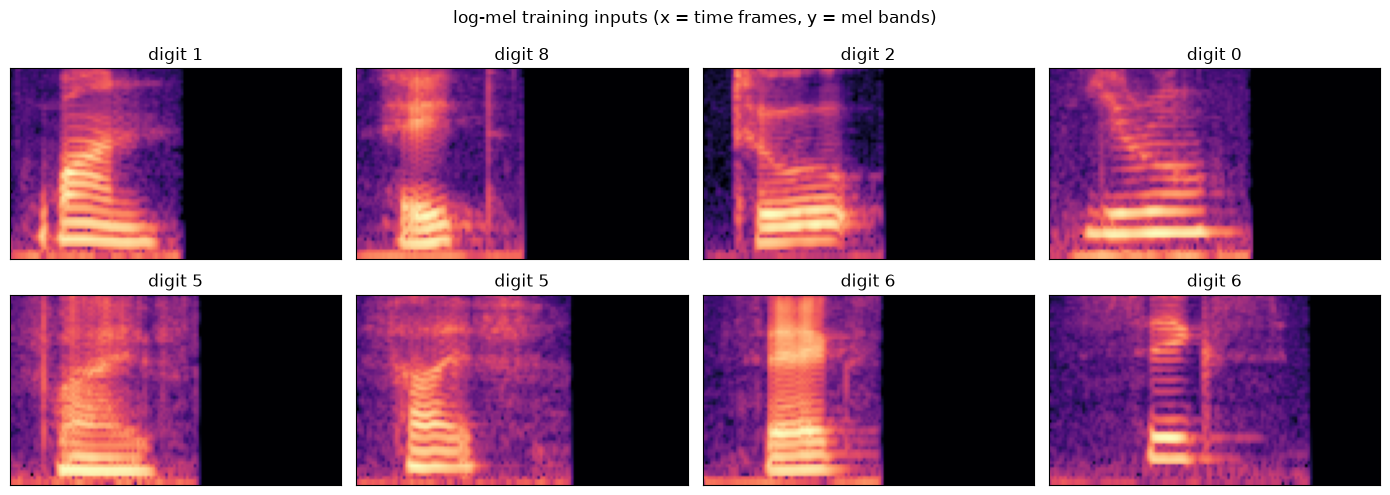

In [ ]:
# WAV -> SPEC
# turns the SAME cached tensors from the cell above (Xtr incl. the Scaper pitch/stretch copies, Xva, Xte) into log-mel spectrograms
# conversion runs per fetch inside CachedDataset, AFTER AddBackground - so the live noise still re-rolls every epoch exactly like the CNN's
# -> same clips, same speaker splits, same augmentation; ONLY the input representation changes (waveform -> spectrogram)

SR = 8000
N_FFT = 256   # this for 32 ms window at 8 kHz
HOP = 64    # 8 ms hop -> 126 frames for 8000 samples
N_MELS = 64   # mel bands (freq axis)
N_FRAMES = 128  # pad 126 -> 128 frames so four stride-2 convs divide evenly (64x128 -> 4x8)
TOP_DB = 80.0   # dynamic range kept, anything quieter than (loudest bin - 80 dB) counts as silence

class ToLogMel:
  # [1, 8000] waveform -> [1, N_MELS, N_FRAMES] log-mel, scaled to [0, 1] (0 = silence, 1 = loudest bin in the clip)
  def __init__(self, sr=SR, n_fft=N_FFT, hop=HOP, n_mels=N_MELS, n_frames=N_FRAMES, top_db=TOP_DB):
    self.mel = torchaudio.transforms.MelSpectrogram(sample_rate=sr, n_fft=n_fft, hop_length=hop, n_mels=n_mels, power=2.0)
    self.n_frames, self.top_db = n_frames, top_db

  def __call__(self, x):
    with torch.no_grad():
      S = self.mel(x)   # [1, n_mels, 126] power
      S_db = 10 * torch.log10(S.clamp(min=1e-10))   # power -> dB
      S_db = S_db - S_db.max()    # 0 dB = loudest bin (clips are peak-normalized already, so this is consistent)
      S = (S_db / self.top_db + 1).clamp(0, 1)    # [-80, 0] dB -> [0, 1]; works nicely with a Sigmoid decoder output + MSE
      T = S.shape[-1]
      if T < self.n_frames:
        S = F.pad(S, (0, self.n_frames - T))    # pad with 0 = silence
      else:
        S = S[..., :self.n_frames]
    return S

to_spec = ToLogMel()

# separate SPEC loaders
# transforms run in order. so noise on the waveform first (train only), THEN the spectrogram
# 11.17 the spec loader gets its OWN noise + shuffle streams, seeded same as the CNN's (train_gen / noise)
# -> after a reset, epoch k shows the AE the same clips in the same order & with the same noise draws as the CNN's epoch k
spec_noise = AddBackground("scaper_bank/background/noise", p=0.2, snr_db=(5, 30), seed=SEED)
spec_train_gen = torch.Generator().manual_seed(SEED)
spec_train_loader = DataLoader(CachedDataset(Xtr, ytr, transforms=[spec_noise, to_spec]), batch_size=64, shuffle=True, generator=spec_train_gen)

def reset_spec_train_stream():   # called right before each AE training stage!!
  spec_noise.reseed(SEED)
  spec_train_gen.manual_seed(SEED)

spec_val_loader = DataLoader(CachedDataset(Xva, yva, transforms=[to_spec]), batch_size=256)
spec_test_loader = DataLoader(CachedDataset(Xte, yte, transforms=[to_spec]), batch_size=256)

print(f"spec splits | train {len(spec_train_loader.dataset)} | val {len(spec_val_loader.dataset)} | test {len(spec_test_loader.dataset)}")
print("(should match the waveform splits:", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset), ")")

# preview from a SEPARATE loader - saw that pulling a batch from spec_train_loader would use up some of its seeded draws
preview_gen = torch.Generator().manual_seed(SEED + 1)
xb, yb = next(iter(DataLoader(CachedDataset(Xtr, ytr, transforms=[to_spec]), batch_size=64, shuffle=True, generator=preview_gen)))
print("spec batch shape:", tuple(xb.shape), "| value range:", f"{xb.min():.2f} to {xb.max():.2f}")   # [64, 1, 64, 128]

# look at a few (clean) training spectrograms (why not)
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, s, y in zip(axes.flat, xb[:8], yb[:8]):
  ax.imshow(s[0].numpy(), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
  ax.set_title(f"digit {int(y)}")
  ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("log-mel training inputs (x = time frames, y = mel bands)")
fig.tight_layout()
plt.show()

In [10]:
# EVAL HELPERS - shared by the waveform CNN and the spec autoencoder! helpful
# (moved out of the CNN training cell so the AE can use them without retraining the CNN)

# MOVED to training cell - confusion matrix helpers!! (named build_confusion so it doesn't clash with sklearn's confusion_matrix function)
def build_confusion(true, pred, n=10):
  cm = np.zeros((n, n), dtype=int)  # 10x10 grid of zeros
  for t, p in zip(true, pred):
    cm[t, p] += 1   # row = TRUE digit, column = PREDICTED digit
  return cm

def plot_confusion(cm, title="Confusion matrix", normalize=False): # (normalize=True turns each row into % of that digit's clips... so the diagonal = per-digit accuracy)
  shown = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100 if normalize else cm
  fig, ax = plt.subplots(figsize=(6.5, 5.5))
  im = ax.imshow(shown, cmap="Blues")
  ax.set_xticks(range(10)); ax.set_yticks(range(10))
  ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit"); ax.set_title(title)
  cutoff = shown.max() / 2    # numbers on dark cells get white text, light cells get black
  for i in range(10):
    for j in range(10):
      if shown[i, j] > 0:   # left empty cells blank to cut clutter
        label = f"{shown[i, j]:.0f}%" if normalize else str(shown[i, j])
        ax.text(j, i, label, ha="center", va="center",
                color="white" if shown[i, j] > cutoff else "black")
  fig.colorbar(im, ax=ax)
  fig.tight_layout()
  return fig    # returned (not shown) so it can also go to TensorBoard !

In [11]:
# SPEC AUTOENCODER
# OK - conv encoder squeezes a [1, 64, 128] log-mel down to a small latent vector z; the decoder mirrors it back out
# a small classifier head reads z - what gives a TEST accuracy to compare against the waveform CNN

class SpecAutoencoder(nn.Module):
  # 11.17 SLIMMED: 4 downsampling layers (was 3) + fewer channels (8, 16, 32, 32 instead of 16, 32, 64)
  # the old size was almost all in the two Linear layers around z (8192 <-> 64). the bottleneck is now 32 x 4 x 8 = 1024
  # -> ~1.13M params down to ~179k (encoder + classifier head ~86k - closer to my 1D CNN's ~56k)
  def __init__(self, latent_dim=64, n_classes=10, n_mels=N_MELS, n_frames=N_FRAMES, channels=(8, 16, 32, 32)):
    super().__init__()

    def down(cin, cout):  # halves height and width
      return nn.Sequential(nn.Conv2d(cin, cout, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

    def up(cin, cout):  # doubles height and width (kernel 4, stride 2, padding 1 -> exactly 2x)
      return nn.Sequential(nn.ConvTranspose2d(cin, cout, kernel_size=4, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

    n_down = len(channels)
    assert n_mels % 2**n_down == 0 and n_frames % 2**n_down == 0, "spectrogram size must divide by 2 for every down layer"
    self.bottleneck = (channels[-1], n_mels // 2**n_down, n_frames // 2**n_down)   # (32, 4, 8)
    flat = channels[-1] * self.bottleneck[1] * self.bottleneck[2]   # 1024

    # encoder: [1, 64, 128] -> [8, 32, 64] -> [16, 16, 32] -> [32, 8, 16] -> [32, 4, 8] -> z
    enc, cin = [], 1
    for c in channels:
      enc.append(down(cin, c))
      cin = c
    self.encoder = nn.Sequential(*enc, nn.Flatten(), nn.Linear(flat, latent_dim))

    # decoder mirrors it: z -> [32, 4, 8] -> [32, 8, 16] -> [16, 16, 32] -> [8, 32, 64] -> [1, 64, 128]
    rev = channels[::-1]
    dec = [nn.Linear(latent_dim, flat), nn.ReLU(), nn.Unflatten(1, self.bottleneck)]
    for cin, cout in zip(rev[:-1], rev[1:]):
      dec.append(up(cin, cout))
    dec += [nn.ConvTranspose2d(rev[-1], 1, kernel_size=4, stride=2, padding=1), # last layer: no BN/ReLU
            nn.Sigmoid()]   # inputs are scaled to [0, 1], so ofc outputs are too
    self.decoder = nn.Sequential(*dec)

    self.classifier = nn.Sequential(
        nn.Linear(latent_dim, 64),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(64, n_classes),
    )

  def forward(self, x):   # reconstruction path
    z = self.encoder(x)
    return self.decoder(z), z

  def classify(self, x):    # classification path (logits)
    return self.classifier(self.encoder(x))

# sanity check on shapes + size
_tmp = SpecAutoencoder()
_recon, _z = _tmp(torch.zeros(2, 1, N_MELS, N_FRAMES))
print("recon:", tuple(_recon.shape), "| latent:", tuple(_z.shape), "| logits:", tuple(_tmp.classify(torch.zeros(2, 1, N_MELS, N_FRAMES)).shape))
_n = lambda m: sum(p.numel() for p in m.parameters())
print(f"params: {_n(_tmp):,} total | encoder {_n(_tmp.encoder):,} | decoder {_n(_tmp.decoder):,} | classifier {_n(_tmp.classifier):,}")
del _tmp, _recon, _z

recon: (2, 1, 64, 128) | latent: (2, 64) | logits: (2, 10)
params: 179,203 total | encoder 80,912 | decoder 93,481 | classifier 4,810


[AE] epoch  1 | train recon MSE 0.01373 | val recon MSE 0.00531
[AE] epoch  2 | train recon MSE 0.00406 | val recon MSE 0.00415
[AE] epoch  3 | train recon MSE 0.00343 | val recon MSE 0.00376
[AE] epoch  4 | train recon MSE 0.00314 | val recon MSE 0.00346
[AE] epoch  5 | train recon MSE 0.00295 | val recon MSE 0.00330
[AE] epoch  6 | train recon MSE 0.00280 | val recon MSE 0.00316
[AE] epoch  7 | train recon MSE 0.00272 | val recon MSE 0.00307
[AE] epoch  8 | train recon MSE 0.00263 | val recon MSE 0.00297
[AE] epoch  9 | train recon MSE 0.00257 | val recon MSE 0.00283
[AE] epoch 10 | train recon MSE 0.00249 | val recon MSE 0.00282
[AE] epoch 11 | train recon MSE 0.00247 | val recon MSE 0.00276
[AE] epoch 12 | train recon MSE 0.00243 | val recon MSE 0.00269
[AE] epoch 13 | train recon MSE 0.00239 | val recon MSE 0.00270
[AE] epoch 14 | train recon MSE 0.00237 | val recon MSE 0.00267
[AE] epoch 15 | train recon MSE 0.00235 | val recon MSE 0.00267
[AE] epoch 16 | train recon MSE 0.00235 

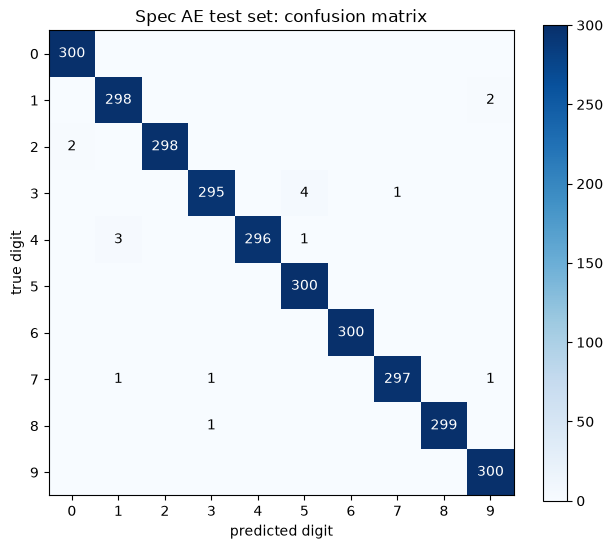

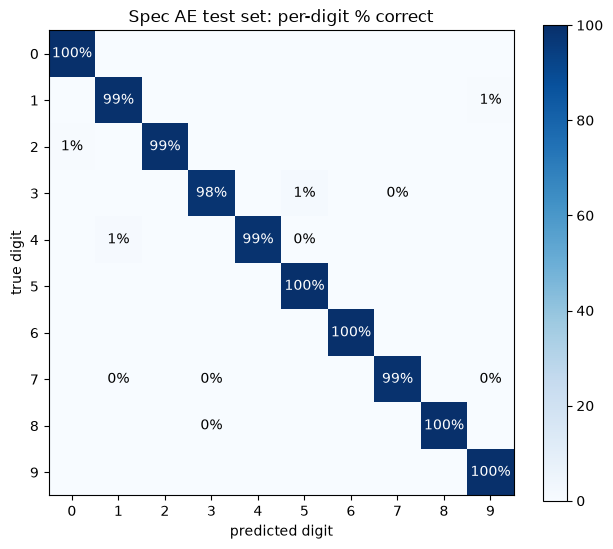

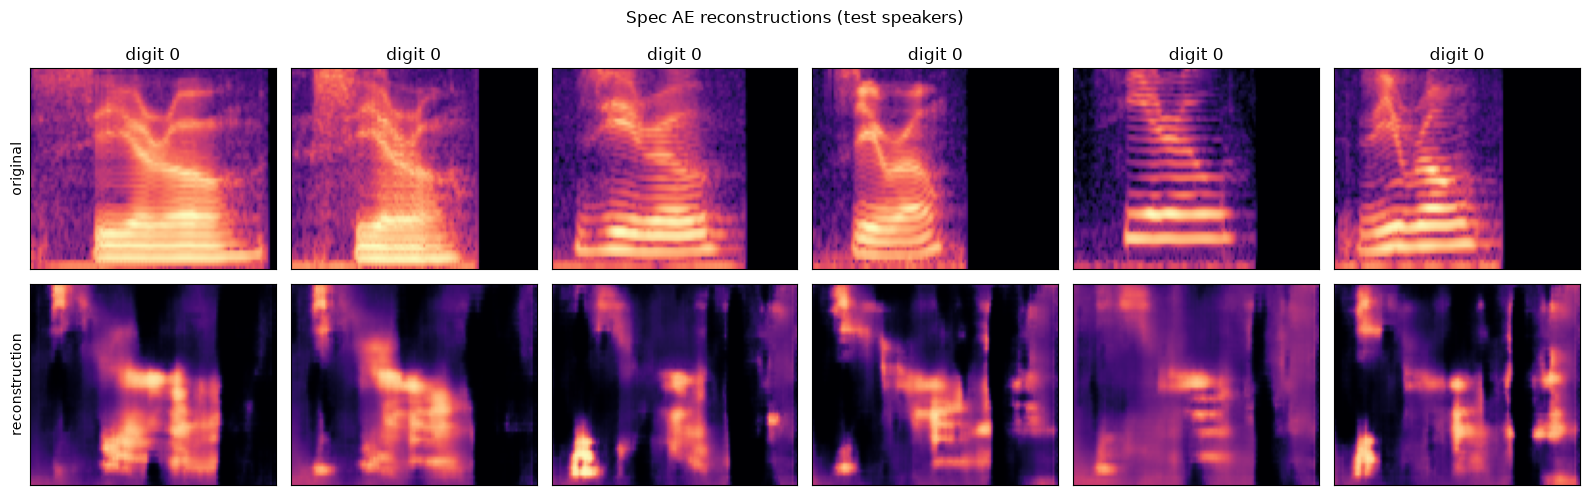

In [12]:
# SPEC AUTOENCODER TRAINING
# stage 1: unsupervised - learn to reconstruct the spectrograms (labels NOT used)
# stage 2: classifier head on the latent z -> val-selected weights -> TEST accuracy + confusion matrix (same test speakers as the CNN)
# and variables are all prefixed ae_ so nothing from the CNN cell (model, hist, te_acc, etc.) gets overwritten

AE_EPOCHS = 20
CLS_EPOCHS = 20
LATENT_DIM = 64
FREEZE_ENCODER = False
# True  = only the head trains (which measures how much digit info the unsupervised latent holds on its own)
# False = encoder is fine-tuned with labels too. think this is the fairer comparison vs the fully supervised CNN

seed_everything()   # 11.17 same seeded weight init every run
ae = SpecAutoencoder(latent_dim=LATENT_DIM).to(device)

# reconstruction stage
recon_fn = nn.MSELoss()
ae_opt = torch.optim.Adam(list(ae.encoder.parameters()) + list(ae.decoder.parameters()), lr=1e-3)

def ae_recon_epoch(loader, train=False):
  ae.train(train)
  total, n = 0.0, 0
  with torch.set_grad_enabled(train):
    for x, _ in loader: # labels ignored
      x = x.to(device)
      recon, _ = ae(x)
      loss = recon_fn(recon, x)
      if train:
        ae_opt.zero_grad()
        loss.backward()
        ae_opt.step()
      total += loss.item() * len(x)
      n += len(x)
  return total / n

reset_spec_train_stream()   # 11.17 stage 1 epochs 1..N see the same data stream as CNN epochs 1..N
ae_hist = {"train_recon": [], "val_recon": []}
best_val_recon, best_ae_state = float("inf"), None
for epoch in range(AE_EPOCHS):
  tr = ae_recon_epoch(spec_train_loader, train=True)
  va = ae_recon_epoch(spec_val_loader)
  ae_hist["train_recon"].append(tr)
  ae_hist["val_recon"].append(va)
  print(f"[AE] epoch {epoch+1:2d} | train recon MSE {tr:.5f} | val recon MSE {va:.5f}")
  if va < best_val_recon:
    best_val_recon, best_ae_state = va, copy.deepcopy(ae.state_dict())

ae.load_state_dict(best_ae_state)
ae_te_recon = ae_recon_epoch(spec_test_loader)
print(f"\n[AE] TEST recon MSE {ae_te_recon:.5f}\n")

# classifier on the latent
if FREEZE_ENCODER:
  for p in ae.encoder.parameters():
    p.requires_grad_(False)
  cls_params = list(ae.classifier.parameters())
else:
  cls_params = list(ae.encoder.parameters()) + list(ae.classifier.parameters())
cls_opt = torch.optim.Adam(cls_params, lr=1e-3)
cls_fn = nn.CrossEntropyLoss()

def ae_cls_epoch(loader, train=False):
  ae.train(train)
  if FREEZE_ENCODER:
    ae.encoder.eval()   # frozen encoder: keep its BatchNorm stats from stage 1 fixed too
  total_loss, correct, n = 0.0, 0, 0
  with torch.set_grad_enabled(train):
    for x, y in loader:
      x, y = x.to(device), y.to(device)
      logits = ae.classify(x)
      loss = cls_fn(logits, y)
      if train:
        cls_opt.zero_grad()
        loss.backward()
        cls_opt.step()
      total_loss += loss.item() * len(y)
      correct += (logits.argmax(dim=1) == y).sum().item()
      n += len(y)
  return total_loss / n, correct / n

reset_spec_train_stream()   # 11.17 ...and so does stage 2 (the stage the test accuracy comes from)
ae_cls_hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_ae_val_acc, best_cls_state = 0.0, None
for epoch in range(CLS_EPOCHS):
  tr_l, tr_a = ae_cls_epoch(spec_train_loader, train=True)
  va_l, va_a = ae_cls_epoch(spec_val_loader)
  for k, v in zip(ae_cls_hist, (tr_l, tr_a, va_l, va_a)):
    ae_cls_hist[k].append(v)
  print(f"[CLS] epoch {epoch+1:2d} | train loss {tr_l:.4f} acc {tr_a:.1%} | val loss {va_l:.4f} acc {va_a:.1%}")
  if va_a > best_ae_val_acc:
    best_ae_val_acc, best_cls_state = va_a, copy.deepcopy(ae.state_dict())

# test once, with the best-on-validation weights (same protocol as the CNN)
ae.load_state_dict(best_cls_state)
ae_te_loss, ae_te_acc = ae_cls_epoch(spec_test_loader)
print(f"\n[SPEC-AE] TEST | loss {ae_te_loss:.4f} | acc {ae_te_acc:.1%}   (encoder {'frozen' if FREEZE_ENCODER else 'fine-tuned'})")
if "te_acc" in globals():
  print(f"[WAV-CNN] TEST | loss {te_loss:.4f} | acc {te_acc:.1%}   (from the CNN cell in this session)")

# test confusion matrix !
ae.eval()
ae_ys, ae_ps = [], []
with torch.no_grad():
  for x, y in spec_test_loader:
    ae_ps += ae.classify(x.to(device)).argmax(dim=1).cpu().tolist()
    ae_ys += y.tolist()
ae_cm_test = build_confusion(ae_ys, ae_ps)
print(f"check: accuracy from matrix = {np.trace(ae_cm_test) / ae_cm_test.sum():.1%} (should match the TEST line above)")
fig_ae_cm = plot_confusion(ae_cm_test, "Spec AE test set: confusion matrix")
fig_ae_cm_pct = plot_confusion(ae_cm_test, "Spec AE test set: per-digit % correct", normalize=True)

# reconstructions on held-out TEST speakers
xs, ys_ = next(iter(spec_test_loader))
idx = torch.randperm(len(xs))[:6]
with torch.no_grad():
  recon, _ = ae(xs[idx].to(device))
fig_recon, axes = plt.subplots(2, 6, figsize=(16, 5))
for j, i in enumerate(idx):
  axes[0, j].imshow(xs[i, 0].numpy(), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
  axes[1, j].imshow(recon[j, 0].cpu().numpy(), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
  axes[0, j].set_title(f"digit {int(ys_[i])}")
  for ax in axes[:, j]:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("original"); axes[1, 0].set_ylabel("reconstruction")
fig_recon.suptitle("Spec AE reconstructions (test speakers)")
fig_recon.tight_layout()
plt.show()

# TensorBoard (*same timestamped RUN_ID folder as the CNN)
writer = SummaryWriter(f"tb_runs/{RUN_ID}/spec_autoencoder")
for i, (tr, va) in enumerate(zip(ae_hist["train_recon"], ae_hist["val_recon"]), start=1):
  writer.add_scalars("ae_recon_mse", {"train": tr, "val": va}, i)
for i in range(1, len(ae_cls_hist["train_loss"]) + 1):
  writer.add_scalars("ae_cls_loss", {"train": ae_cls_hist["train_loss"][i - 1], "val": ae_cls_hist["val_loss"][i - 1]}, i)
  writer.add_scalars("ae_cls_acc", {"train": ae_cls_hist["train_acc"][i - 1], "val": ae_cls_hist["val_acc"][i - 1]}, i)
writer.add_scalar("test/ae_acc", ae_te_acc)
writer.add_scalar("test/ae_recon_mse", ae_te_recon)
writer.add_figure("Confusion_Matrix_Test_SpecAE", fig_ae_cm, close=False)
writer.add_figure("Reconstructions_Test_SpecAE", fig_recon, close=False)
writer.close()

epoch  1 | train loss 0.8850 acc 73.5% | val loss 0.4092 acc 88.1%
epoch  2 | train loss 0.2936 acc 91.7% | val loss 0.2977 acc 90.1%
epoch  3 | train loss 0.2214 acc 93.5% | val loss 0.4363 acc 83.3%
epoch  4 | train loss 0.1547 acc 95.3% | val loss 0.1994 acc 93.4%
epoch  5 | train loss 0.1158 acc 96.6% | val loss 0.1974 acc 94.6%
epoch  6 | train loss 0.0950 acc 97.2% | val loss 0.5779 acc 86.7%
epoch  7 | train loss 0.0842 acc 97.4% | val loss 4.0664 acc 42.7%
epoch  8 | train loss 0.0694 acc 98.0% | val loss 1.1416 acc 74.1%
epoch  9 | train loss 0.0664 acc 97.9% | val loss 9.2744 acc 27.2%
epoch 10 | train loss 0.0559 acc 98.3% | val loss 13.5884 acc 26.2%
epoch 11 | train loss 0.0592 acc 98.1% | val loss 5.6003 acc 34.9%
epoch 12 | train loss 0.0457 acc 98.6% | val loss 5.9976 acc 41.1%
epoch 13 | train loss 0.0428 acc 98.7% | val loss 15.8604 acc 15.9%
epoch 14 | train loss 0.0508 acc 98.5% | val loss 2.0004 acc 64.9%
epoch 15 | train loss 0.0425 acc 98.7% | val loss 41.8805 ac

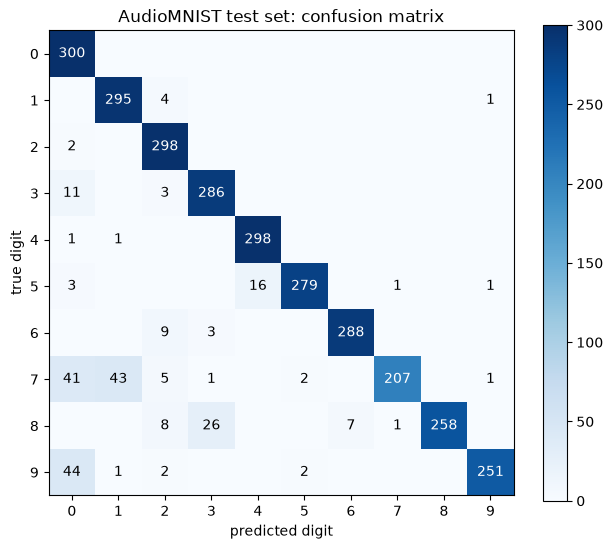

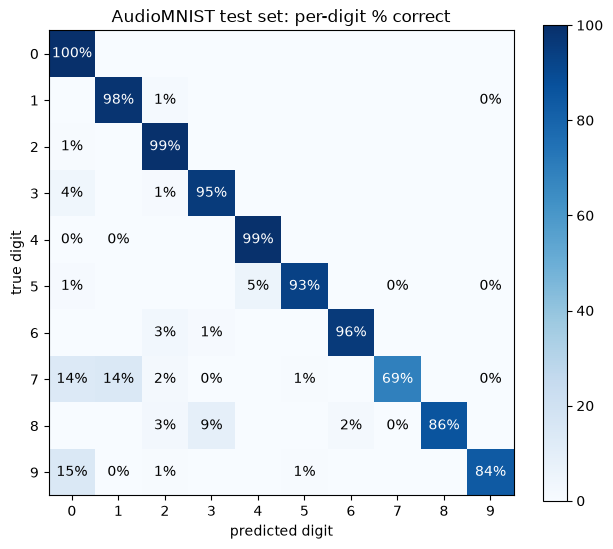

In [13]:
# WAV CNN TRAINING

# 1D CNN (on the raw waveform)
class AudioCNN1D(nn.Module):
  def __init__(self, n_classes=10):
    super().__init__()
    self.features = nn.Sequential(
        nn.BatchNorm1d(1),   # ADDED! input batch norm - normalizes the raw waveform [batch, 1, 8000] before the first conv

      # 32 learned filters; 80 samples = 10 ms at 8 kHz; stride 8; output length is 1001 for 8000 input (padding=36 would give exactly 1000)
        nn.Conv1d(1, 32, kernel_size=80, stride=8, padding=40),
        nn.BatchNorm1d(32),
        nn.ReLU(),
        nn.MaxPool1d(4),

        nn.Conv1d(32, 64, kernel_size=5, padding=2),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.MaxPool1d(4),

        nn.Conv1d(64, 128, kernel_size=5, padding=2),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.AdaptiveAvgPool1d(1),
    )
    self.classifier = nn.Linear(128, n_classes)

  def forward(self, x):
    x = self.features(x)
    return self.classifier(x.flatten(1))

# 11.17 reset seeds + the train loader's noise/shuffle streams, so this matches the AE's data stream epoch for epoch
seed_everything()
noise.reseed(SEED)
train_gen.manual_seed(SEED)
model = AudioCNN1D().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# a single function including train / val / test passes
def run_epoch(loader, train=False):
  model.train(train) # train mode
  total_loss, correct, n = 0.0, 0, 0
  with torch.set_grad_enabled(train):
    for x, y in loader:
      x, y = x.to(device), y.to(device)
      logits = model(x)
      loss = loss_fn(logits, y)

      if train:
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

      total_loss += loss.item() * len(y)
      correct += (logits.argmax(dim=1) == y).sum().item()
      n += len(y)

  return total_loss / n, correct / n

# (build_confusion / plot_confusion now live in the EVAL HELPERS cell, shared with the spec autoencoder)

# 11.10 FOR CONF MX now - running a whole loader through the model and return (true labels, predictions)
def predict_loader(loader):
  model.eval()
  ys, ps = [], []
  with torch.no_grad():
    for x, y in loader:
      ps += model(x.to(device)).argmax(dim=1).cpu().tolist()
      ys += y.tolist()
  return ys, ps

# compile history for plotting
hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

# train, validate each epoch and keeping the best weights
best_val_acc, best_state = 0.0, None
for epoch in range(20):
  tr_loss, tr_acc = run_epoch(train_loader, train=True)
  va_loss, va_acc = run_epoch(val_loader)

  hist["train_loss"].append(tr_loss)
  hist["train_acc"].append(tr_acc)
  hist["val_loss"].append(va_loss)
  hist["val_acc"].append(va_acc)

  print(f"epoch {epoch+1:2d} | train loss {tr_loss:.4f} acc {tr_acc:.1%} | val loss {va_loss:.4f} acc {va_acc:.1%}")

  if va_acc > best_val_acc:
    best_val_acc = va_acc
    best_state = copy.deepcopy(model.state_dict())

# test once, using the best-on-validation weights
model.load_state_dict(best_state)
te_loss, te_acc = run_epoch(test_loader)
print(f"\nTEST | loss {te_loss:.4f} | acc {te_acc:.1%}")

# 11.10 CALL CONF MX
ys, ps = predict_loader(test_loader)
cm_test = build_confusion(ys, ps)
print(f"check: accuracy from matrix = {np.trace(cm_test) / cm_test.sum():.1%} (should match the TEST line above)")
fig_cm_test = plot_confusion(cm_test, "AudioMNIST test set: confusion matrix")
fig_cm_test_pct = plot_confusion(cm_test, "AudioMNIST test set: per-digit % correct", normalize=True)

# replace initial plt. function below with TB now.
# use 'tr_loss', 'tr_acc', 'va_loss', 'va_acc' as variables for plotting -> eventually switch to eval/val/train.
# have to create separate 'for loop'?

writer = SummaryWriter(f"tb_runs/{RUN_ID}/training")  # writer will output to ./runs/ directory by default
# 11.10 CONF MX on Test to TensorBoard
writer.add_figure("Confusion_Matrix_Test", fig_cm_test, close=False) # close=False just keeps visible in notebook
r = 5 # ADJUST - value just from tutorial.
for i in range(1, len(hist["train_loss"]) + 1):
  writer.add_scalars("loss", {"train": hist["train_loss"][i - 1], "val": hist["val_loss"][i - 1]}, i)
writer.close()
# this call adds three values to the same scalar plot with the tag
# 'loss' in TensorBoard's scalar section

# add accuracy

###
# graphing of train vs. validation over training
# ep = range(1, len(hist["train_loss"]) + 1)
# fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# axes[0].plot(ep, hist["train_loss"], label="train")
# axes[0].plot(ep, hist["val_loss"], label="validation")
# axes[0].set_title("loss per epoch")
# axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss")

# axes[1].plot(ep, [a * 100 for a in hist["train_acc"]], label="train")
# axes[1].plot(ep, [a * 100 for a in hist["val_acc"]], label="validation")
# axes[1].set_title("accuracy per epoch")
# axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (%)")

# for ax in axes:
#   ax.grid(alpha=0.3)
#   ax.legend()
# plt.tight_layout()
# plt.show()

# # per-epoch table
# print(pd.DataFrame(hist, index=pd.Index(ep, name="epoch")).round(4))

File selected: /Users/madelinemccormack/Documents/GitHub/Spec_AudioMNIST_Autoencoder/audio-mm/1-M-01.wav
my selected (processed) clip:


prediction: 1 (99.5% confident)
Top 3:  1 (99.5%),  9 (0.5%),  0 (0.0%)
true digit: 1 -> correct


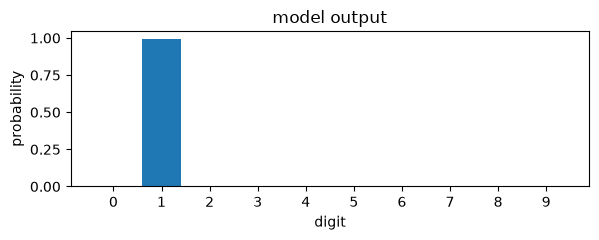

my selected (processed) clip:


prediction: 0 (100.0% confident)
Top 3:  0 (100.0%),  9 (0.0%),  1 (0.0%)
true digit: 0 -> correct
0-M-01.wav           true=0 pred=0 ok
my selected (processed) clip:


prediction: 1 (99.5% confident)
Top 3:  1 (99.5%),  9 (0.5%),  0 (0.0%)
true digit: 1 -> correct
1-M-01.wav           true=1 pred=1 ok
my selected (processed) clip:


prediction: 0 (99.6% confident)
Top 3:  0 (99.6%),  7 (0.2%),  2 (0.1%)
true digit: 2 -> wrong
2-M-01.wav           true=2 pred=0 X
my selected (processed) clip:


prediction: 0 (60.2% confident)
Top 3:  0 (60.2%),  9 (35.0%),  1 (2.0%)
true digit: 3 -> wrong
3-M-01.wav           true=3 pred=0 X
my selected (processed) clip:


prediction: 1 (99.4% confident)
Top 3:  1 (99.4%),  4 (0.5%),  0 (0.2%)
true digit: 4 -> wrong
4-M-01.wav           true=4 pred=1 X
my selected (processed) clip:


prediction: 9 (93.3% confident)
Top 3:  9 (93.3%),  1 (6.7%),  5 (0.0%)
true digit: 5 -> wrong
5-M-01.wav           true=5 pred=9 X
my selected (processed) clip:


prediction: 0 (47.7% confident)
Top 3:  0 (47.7%),  2 (25.0%),  7 (13.7%)
true digit: 6 -> wrong
6-M-01.wav           true=6 pred=0 X
my selected (processed) clip:


prediction: 9 (96.1% confident)
Top 3:  9 (96.1%),  7 (3.0%),  1 (0.8%)
true digit: 7 -> wrong
7-M-01.wav           true=7 pred=9 X
my selected (processed) clip:


prediction: 0 (79.6% confident)
Top 3:  0 (79.6%),  3 (17.4%),  2 (2.5%)
true digit: 8 -> wrong
8-M-01.wav           true=8 pred=0 X
my selected (processed) clip:


prediction: 9 (100.0% confident)
Top 3:  9 (100.0%),  1 (0.0%),  7 (0.0%)
true digit: 9 -> correct
9-M-01.wav           true=9 pred=9 ok

Accuracy on my recordings: 0.3


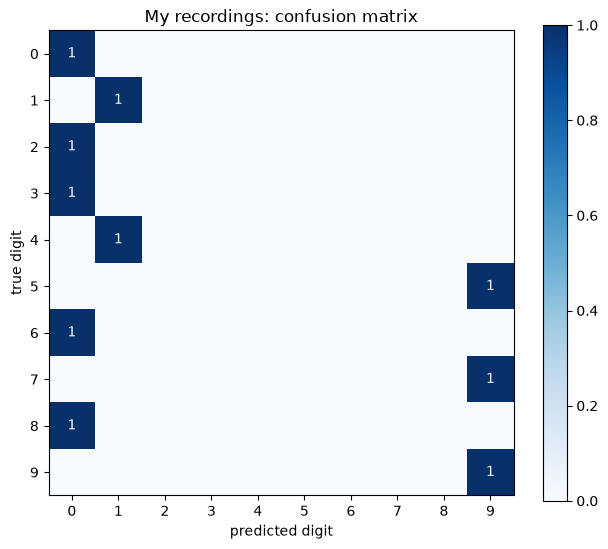

In [14]:
# load, play, and test own audio samples against CNN
# 10.25 added TensorBoard; just using model charting (e.g. over epochs) for now

# from google.colab import drive
# drive.mount('/content/drive')

audio_mm_folder = Path.cwd() / "audio-mm"

AUDIO_EXTS = {".wav", ".m4a"}

def get_random_file(folder_path):
    # only picks audio files within the folder
    files = [f for f in Path(folder_path).iterdir() if f.is_file() and f.suffix.lower() in AUDIO_EXTS]
    if not files:
        return None  # if folder is empty or only contains subdirectories

    # return a randomly selected file path
    random_file = random.choice(files)
    print(f"File selected: {random_file}")
    return random_file

# do same preprocessing that the training data got (mono, 8 kHz, 8000 samples, peak-norm'd)
# ADDED: trim the silence around the digit first, so it looks like an AudioMNIST clip
# (short digit near the start, then zero padding) instead of a full second of room audio
def prepare_clip(path, target_sr=8000, num_samples=8000, top_db=20, lead=0.1, tail=0.05):
  waveform, sr = torchaudio.load(str(path))
  waveform = waveform.mean(dim=0, keepdim=True)
  if sr != target_sr:
    waveform = torchaudio.functional.resample(waveform, sr, target_sr)

  # find where the digit is: short frames (32 ms) quieter than top_db below the loudest frame count as silence
  # then keep from 'lead' sec before it to 'tail' sec after (AudioMNIST digits start ~0.1 sec in on average, hence the default lead)
  # note: with a noisy room the noise floor can sit within ~10-20 dB of the voice, so less gets trimmed
  #   lowering top_db trims more, but below ~15 it starts cutting quiet parts of the digit (like the 's' sounds in six)
  _, (start, end) = librosa.effects.trim(waveform[0].numpy(), top_db=top_db, frame_length=256, hop_length=64)
  start = max(start - int(lead * target_sr), 0)
  end = min(end + int(tail * target_sr), waveform.shape[1])
  waveform = waveform[:, start:end]

  n = waveform.shape[1] # pad/trim to 1 sec
  if n < num_samples:
    waveform = F.pad(waveform, (0, num_samples - n))
  else:
    waveform = waveform[:, :num_samples]

  return waveform / waveform.abs().max().clamp(min=1e-8)  # again, same peak normalization

# just run one file through the model
def classify_file(path, show=True):
  wav = prepare_clip(path)
  model.eval() # returning logits / raw scores. one per digit (shape[1, 10])
  with torch.no_grad():
    probs = torch.softmax(model(wav.unsqueeze(0).to(device)), dim=1)[0].cpu() # input [1, 1, 8000]; removes the batch-of-one dimension
  pred = int(probs.argmax())

  # get the true label from the filename with assumption the first number is the digit
  try:
    true = int(Path(path).name.split("-")[0])
  except ValueError:
    true = None

  # CHANGED SLIGHTLY -- bar chart only built when show=True now
  # create explicit figure and axes objects -- can use either with plt.show() in notebook or for TB
  fig = None
  if show:
    fig, ax = plt.subplots(figsize=(6, 2.5))
    ax.bar(range(10), probs.numpy())
    ax.set_xticks(range(10))
    ax.set_xlabel("digit")
    ax.set_ylabel("probability")
    ax.set_title("model output")
    fig.tight_layout()

  print("my selected (processed) clip:")
  display(Audio(wav.squeeze(0).numpy(), rate=8000))
  top_p, top_d = probs.topk(3)  # returns the 3 largest values (in probs) -> top_p probs' values, top_d digits
  print(f"prediction: {pred} ({probs[pred]:.1%} confident)")
  print("Top 3:", ", ".join(f" {int(d)} ({p:.1%})" for p, d in zip(top_p, top_d)))
  if true is not None:
    print(f"true digit: {true} -> {'correct' if pred == true else 'wrong'}")
  plt.show()  # CHANGED -- plt.show the single-clip bar chart right here then close it out (so it doesn't pile up with later figures)

  # OLD 10-GRAPH IMPLEMENTATION
  # if show:
  #   print("my selected (processed) clip:")
  #   display(Audio(wav.squeeze(0).numpy(), rate=8000))
  #   top_p, top_d = probs.topk(3)  # returns the 3 largest values (in probs) -> top_p probs' values, top_d digits
  #   print(f"prediction: {pred} ({probs[pred]:.1%} confident)")
  #   print("Top 3:", ", ".join(f" {int(d)} ({p:.1%})" for p, d in zip(top_p, top_d)))
  #   if true is not None:
  #     print(f"true digit: {true} -> {'correct' if pred == true else 'wrong'}")

  return pred, true, fig  # REMEMBER 'fig' is changed to None now for show=False

# one random recording - but can switch to cycling through all 10 of them
random_audio_file = get_random_file(str(audio_mm_folder))
pred, true, fig = classify_file(random_audio_file)

# use all of my recordings at once + an overall score
results = []
for f in sorted(Path(str(audio_mm_folder)).iterdir()):
  if f.suffix.lower() in AUDIO_EXTS:
    pred, true, run_fig = classify_file(f, show=False)
    results.append((f.name, true, pred))
    print(f"{f.name:20s} true={true} pred={pred} {'ok' if pred == true else 'X'}")
scored = [(t, p) for _, t, p in results if t is not None]
if scored:
  model_total_acc = sum(t == p for t, p in scored) / len(scored)
  print(f"\nAccuracy on my recordings: {model_total_acc}")

# ADDED - calling confusion matrix of my own recordings (to replace the per-digit matplot graphs)
fig_cm = None
if scored:
  cm = build_confusion([t for t, p in scored], [p for t, p in scored])
  fig_cm = plot_confusion(cm, "My recordings: confusion matrix")

# calculate accuracy per unique digit label (0-9) -> specifically for TB usage, rather than a crude matplot graph I was doing before
accuracy_per_digit = {}
for digit in range(10):
  digit_samples = [pair for pair in scored if pair[0] == digit]
  if len(digit_samples) > 0:
    acc = sum(t == p for t, p in digit_samples) / len(digit_samples)
    accuracy_per_digit[digit] = acc
  else:
    accuracy_per_digit[digit] = 0.0 # no samples for this digit in custom dataset

writer = SummaryWriter(f"tb_runs/{RUN_ID}/my_recordings")
for digit, acc in accuracy_per_digit.items():
  writer.add_scalar("Accuracy_Per_Digit", acc, global_step=digit) # kind of would have preferred this to show probability up to 1f (to be as clear as possible + show how bad the model's accuracy was against my inputs)

writer.close()

# ADDED - also sending the confusion matrix to TensorBoard (close=False so it still displays in the notebook)
if fig_cm is not None:
  writer.add_figure("Confusion_Matrix_My_Recordings", fig_cm, close=False)

writer.close()


my selected (processed) clip: 1-M-01.wav


prediction: 1 (100.0% confident)
Top 3:  1 (100.0%),  9 (0.0%),  5 (0.0%)
true digit: 1 -> correct


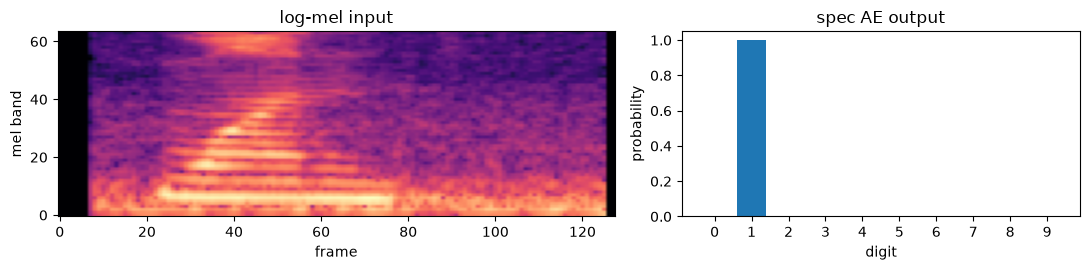

      file  true  cnn_pred  ae_pred
0-M-01.wav     0         0        0
1-M-01.wav     1         1        1
2-M-01.wav     2         0        2
3-M-01.wav     3         0        3
4-M-01.wav     4         1        4
5-M-01.wav     5         9        9
6-M-01.wav     6         0        7
7-M-01.wav     7         9        7
8-M-01.wav     8         0        3
9-M-01.wav     9         9        9

Accuracy on my recordings | spec AE: 70.0% | wav CNN: 30.0%


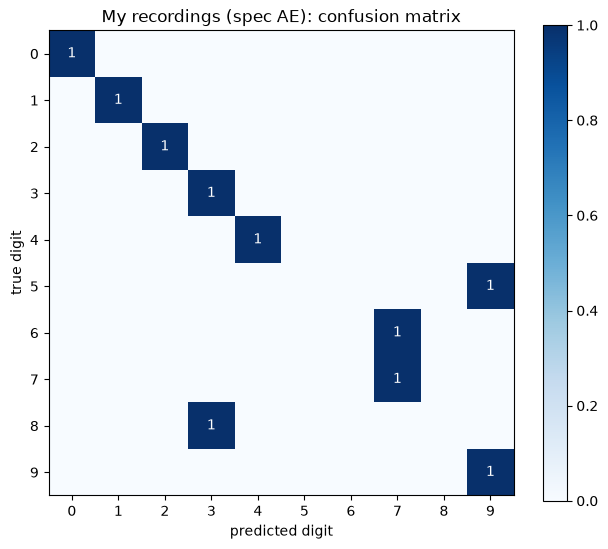

In [15]:
# load, play, and test own audio samples against the SPEC AUTOENCODER
# same preprocessing as the CNN cell above (prepare_clip: mono, 8 kHz, trim silence, pad to 1 s, peak-norm), then to_spec -> ae.classify
# (reuses prepare_clip, get_random_file, AUDIO_EXTS, audio_mm_folder, random_audio_file and results from the CNN recordings cell above)

def classify_file_ae(path, show=True):
  wav = prepare_clip(path)  # [1, 8000] - identical waveform to what the CNN got
  spec = to_spec(wav) # [1, 64, 128] - same transform the val/test clips got
  ae.eval()
  with torch.no_grad():
    probs = torch.softmax(ae.classify(spec.unsqueeze(0).to(device)), dim=1)[0].cpu()   # input [1, 1, 64, 128]
  pred = int(probs.argmax())

  try:
    true = int(Path(path).name.split("-")[0])   # same filename convention as the CNN cell
  except ValueError:
    true = None

  if show:
    print("my selected (processed) clip:", Path(path).name)
    display(Audio(wav.squeeze(0).numpy(), rate=8000))
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={"width_ratios": [1.4, 1]})
    ax0.imshow(spec[0].numpy(), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    ax0.set_title("log-mel input"); ax0.set_xlabel("frame"); ax0.set_ylabel("mel band")
    ax1.bar(range(10), probs.numpy())
    ax1.set_xticks(range(10)); ax1.set_xlabel("digit"); ax1.set_ylabel("probability"); ax1.set_title("spec AE output")
    fig.tight_layout()
    top_p, top_d = probs.topk(3)
    print(f"prediction: {pred} ({probs[pred]:.1%} confident)")
    print("Top 3:", ", ".join(f" {int(d)} ({p:.1%})" for p, d in zip(top_p, top_d)))
    if true is not None:
      print(f"true digit: {true} -> {'correct' if pred == true else 'wrong'}")
    plt.show()

  return pred, true

# the SAME random clip the CNN just classified, for a direct comparison
classify_file_ae(random_audio_file)

# all of my recordings, side by side with the CNN's predictions from the cell above
cnn_pred_by_file = {name: p for name, _, p in results}
ae_results = []
for f in sorted(Path(str(audio_mm_folder)).iterdir()):
  if f.suffix.lower() in AUDIO_EXTS:
    pred, true = classify_file_ae(f, show=False)
    ae_results.append((f.name, true, pred))
rec_table = pd.DataFrame([(n, t, cnn_pred_by_file.get(n), p) for n, t, p in ae_results],
                         columns=["file", "true", "cnn_pred", "ae_pred"])
print(rec_table.to_string(index=False))

ae_scored = [(t, p) for _, t, p in ae_results if t is not None]
if ae_scored:
  ae_rec_acc = sum(t == p for t, p in ae_scored) / len(ae_scored)
  print(f"\nAccuracy on my recordings | spec AE: {ae_rec_acc:.1%} | wav CNN: {model_total_acc:.1%}")

  cm_rec_ae = build_confusion([t for t, _ in ae_scored], [p for _, p in ae_scored])
  fig_cm_rec_ae = plot_confusion(cm_rec_ae, "My recordings (spec AE): confusion matrix")

  writer = SummaryWriter(f"tb_runs/{RUN_ID}/my_recordings_spec_ae")
  for digit in range(10):
    d = [(t, p) for t, p in ae_scored if t == digit]
    writer.add_scalar("Accuracy_Per_Digit", sum(t == p for t, p in d) / len(d) if d else 0.0, global_step=digit)
  writer.add_figure("Confusion_Matrix_My_Recordings_SpecAE", fig_cm_rec_ae, close=False)
  writer.close()

my spectrograms: (10, 1, 64, 128)

held-out AudioMNIST test speakers | mean recon MSE 0.00277 (should match [AE] TEST recon MSE 0.00277)
my recordings                     | mean recon MSE 0.00821  (3.0x the test speakers)

0-M-01.wav   digit 0 | recon MSE 0.00828 | worse than 100% of test-speaker clips
1-M-01.wav   digit 1 | recon MSE 0.00702 | worse than 100% of test-speaker clips
2-M-01.wav   digit 2 | recon MSE 0.00727 | worse than 100% of test-speaker clips
3-M-01.wav   digit 3 | recon MSE 0.00783 | worse than 100% of test-speaker clips
4-M-01.wav   digit 4 | recon MSE 0.00813 | worse than 100% of test-speaker clips
5-M-01.wav   digit 5 | recon MSE 0.00771 | worse than 100% of test-speaker clips
6-M-01.wav   digit 6 | recon MSE 0.00808 | worse than 100% of test-speaker clips
7-M-01.wav   digit 7 | recon MSE 0.01151 | worse than 100% of test-speaker clips
8-M-01.wav   digit 8 | recon MSE 0.00727 | worse than 100% of test-speaker clips
9-M-01.wav   digit 9 | recon MSE 0.00894 | worse

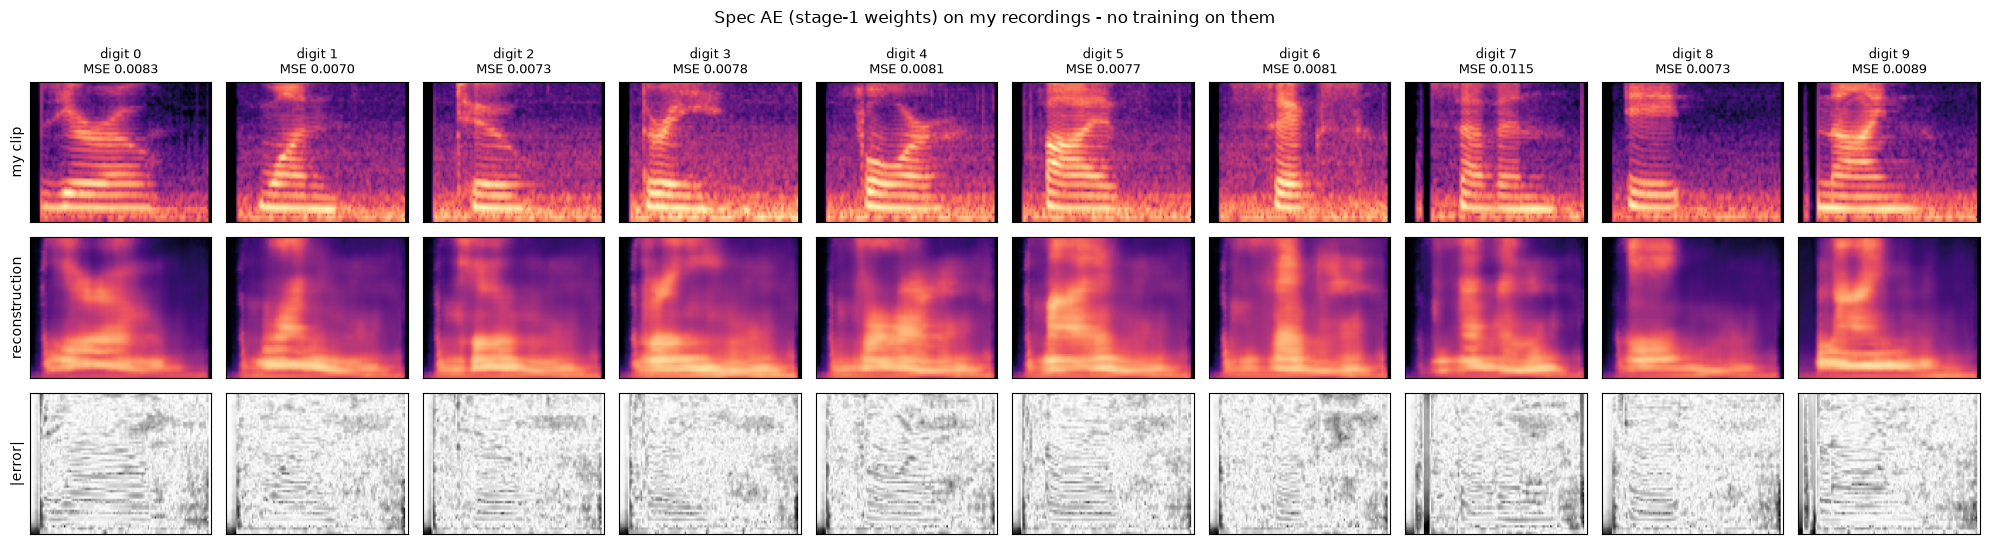

Part A - pretrained AE, no training on my clips


,original (prepare_clip),AE input spec -> Griffin-Lim,AE reconstruction -> Griffin-Lim
digit 0,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 1,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 2,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 3,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 4,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 5,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 6,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 7,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 8,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 9,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.


[FIT] step    1 | recon MSE on my 10 clips 0.03962
[FIT] step  100 | recon MSE on my 10 clips 0.00273
[FIT] step  200 | recon MSE on my 10 clips 0.00208
[FIT] step  300 | recon MSE on my 10 clips 0.00174
[FIT] step  400 | recon MSE on my 10 clips 0.00151
[FIT] step  500 | recon MSE on my 10 clips 0.00134

mean recon MSE on my clips | pretrained 0.00821 -> after fitting to them 0.00136
      file  digit  pretrained_mse  fitted_mse
0-M-01.wav      0         0.00828     0.00137
1-M-01.wav      1         0.00702     0.00132
2-M-01.wav      2         0.00727     0.00138
3-M-01.wav      3         0.00783     0.00140
4-M-01.wav      4         0.00813     0.00138
5-M-01.wav      5         0.00771     0.00137
6-M-01.wav      6         0.00808     0.00135
7-M-01.wav      7         0.01151     0.00121
8-M-01.wav      8         0.00727     0.00139
9-M-01.wav      9         0.00894     0.00139


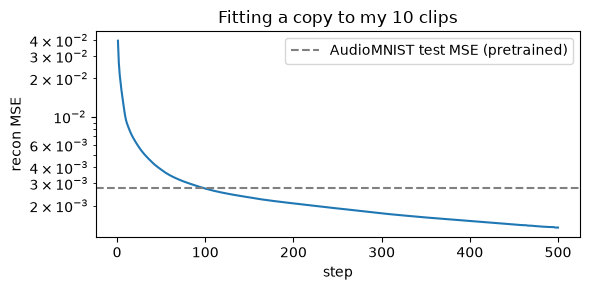

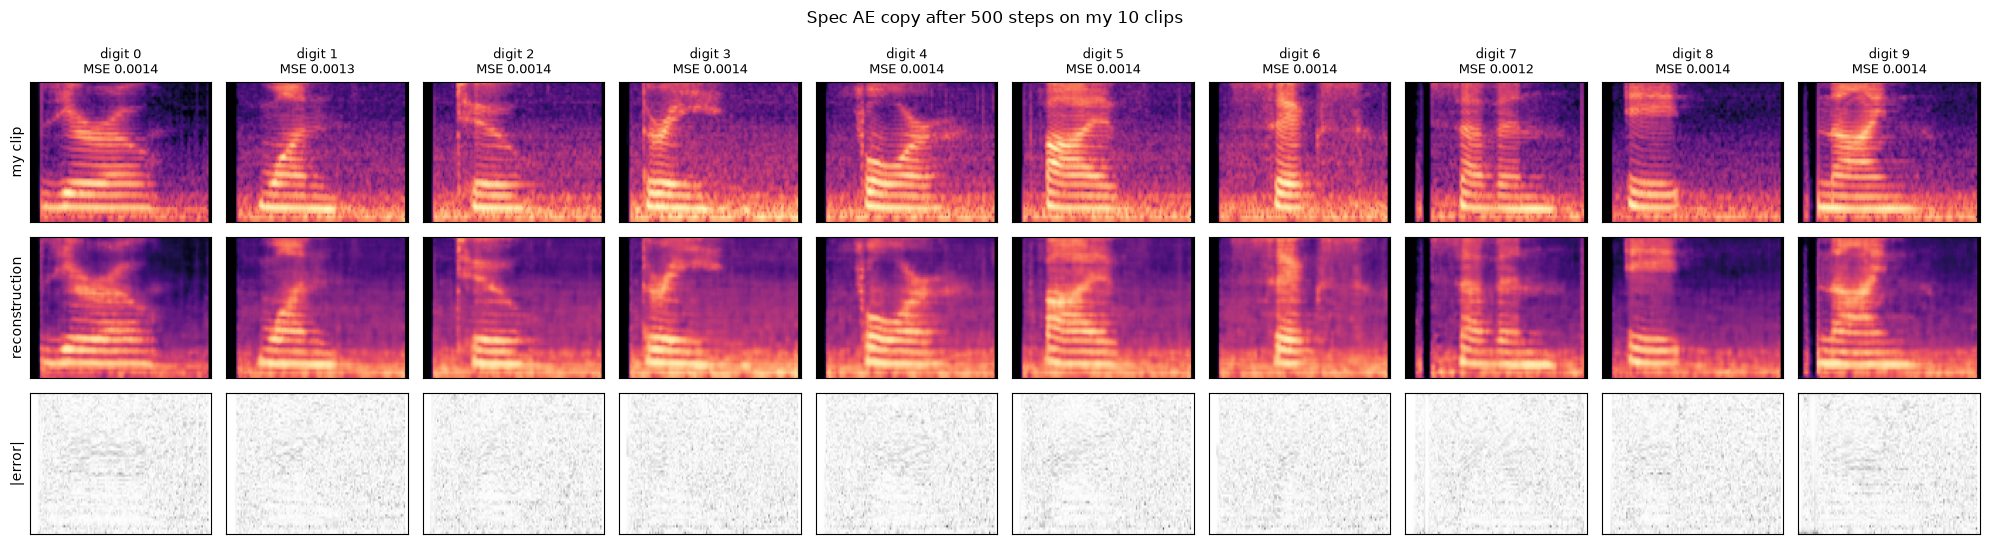

Part B - copy fitted for 500 steps on my 10 clips


,AE input spec -> Griffin-Lim,pretrained recon -> Griffin-Lim,fitted recon -> Griffin-Lim
digit 0,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 1,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 2,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 3,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 4,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 5,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 6,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 7,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 8,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
digit 9,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.


In [16]:
# 11.19 RECONSTRUCT MY OWN RECORDINGS with the spec AE (1 clip per digit, audio-mm/)
# question: can the AE trained on AudioMNIST speakers reproduce MY 10 log-mel spectrograms?
# Part A = pure inference, no training on my clips -> does reconstruction generalize to a brand-new speaker + mic + room?
# Part B = (optional) fine-tune a COPY on just my 10 clips -> how close can it get when it's allowed to memorize them?
# ALSO: nothing in here touches `ae` (the classifier the cells above use), so those cells give the same results after this runs

# IMPORTANT REMINDER: use the STAGE-1 (reconstruction) weights = best_ae_state, NOT the current `ae`
# with FREEZE_ENCODER = False, stage 2 kept updating the encoder for classification while the decoder sat still,
# so the current ae.encoder no longer produces the z's the decoder learned to decode -> its reconstructions would look worse than they really are
from IPython.display import HTML   # for the audio-player tables below (Audio, display already come from the imports cell)

ae_rec = SpecAutoencoder(latent_dim=LATENT_DIM).to(device)
ae_rec.load_state_dict(best_ae_state)
ae_rec.eval()   # eval = BatchNorm uses its running stats from AudioMNIST training (not stats from a batch of my 10 clips)

# my clips -> the SAME pipeline val/test and the classify cells use: prepare_clip (mono, 8 kHz, trim, pad to 1 s, peak-norm) -> to_spec
my_files = sorted(f for f in audio_mm_folder.iterdir() if f.suffix.lower() in AUDIO_EXTS)
my_wavs = [prepare_clip(f) for f in my_files]   # [1, 8000] each - kept so the originals can be played below
my_specs = torch.stack([to_spec(w) for w in my_wavs])   # [10, 1, 64, 128], values in [0, 1]
my_digits = [int(f.name.split("-")[0]) for f in my_files]
print("my spectrograms:", tuple(my_specs.shape))

def recon_and_mse(net, X, batch=256):
  # per-clip MSE - nn.MSELoss avg's the same sq'd error over every pixel, so these will be on the same scale as the [AE] lines above
  net.eval()
  Rs = []
  with torch.no_grad():
    for i in range(0, len(X), batch):
      R, _ = net(X[i:i + batch].to(device))
      Rs.append(R.cpu())
  R = torch.cat(Rs)
  return R, ((R - X) ** 2).mean(dim=(1, 2, 3))

# SPEC -> WAV, so I can actually LISTEN to what goes into the AE and what comes out
# the AE only ever sees magnitudes (no phase) -> Griffin-Lim iteratively guesses a phase consistent with those magnitudes
# so expect some metallic/phasey artifacts even on the INPUT spec. that part is the vocoder, not the AE:
# judge "reconstruction vs input spec", not "reconstruction vs original"
# undoes ToLogMel step by step with the SAME settings (htk mel scale, no norm, power=2.0) so the inverse lines up exactly
N_REAL_FRAMES = 1 + 8000 // HOP   # 126 real frames; ToLogMel padded 2 silent ones on to reach N_FRAMES = 128
# driver="gelsd": at 8 kHz / n_fft 256 the bins are 31 Hz apart, so a few of the narrow low mel filters catch NO bin (all-zero rows)
# -> the filterbank is rank-deficient and the default "gels" solver errors out; gelsd (SVD) handles that
inv_mel = torchaudio.transforms.InverseMelScale(n_stft=N_FFT // 2 + 1, n_mels=N_MELS, sample_rate=SR, driver="gelsd")
griffin_lim = torchaudio.transforms.GriffinLim(n_fft=N_FFT, hop_length=HOP, power=2.0, n_iter=64, length=8000)

def spec_to_wav(S):
  """[1, N_MELS, N_FRAMES] log-mel scaled to [0, 1] -> 1-D numpy waveform at SR (peak-normalized)"""
  with torch.no_grad():
    S = S.detach().cpu().float().reshape(N_MELS, -1)[:, :N_REAL_FRAMES]   # drop the pad frames
    mel_power = 10 ** ((S - 1) * TOP_DB / 10)   # [0, 1] -> [-80, 0] dB -> power (relative to the loudest bin; absolute level was already gone)
    lin_power = inv_mel(mel_power).clamp(min=0)   # [N_FFT//2 + 1, 126], least-squares un-mel
    with torch.random.fork_rng(devices=[]):   # GL starts from a random phase -> seed it so the audio is the same every run,
      torch.manual_seed(SEED)                 # without disturbing the global RNG that Part B's seed_everything() relies on
      wav = griffin_lim(lin_power)
    wav = wav / wav.abs().max().clamp(min=1e-8)
  return wav.numpy()

def play_table(digits, columns, sr=SR):
  # one row per clip, one audio player per column; columns = {"header": [wav per clip, ...]}
  head = "".join(f"<th>{name}</th>" for name in columns)
  rows = ""
  for i, d in enumerate(digits):
    players = "".join(f"<td>{Audio(wavs[i], rate=sr)._repr_html_()}</td>" for wavs in columns.values())
    rows += f"<tr><td><b>digit {d}</b></td>{players}</tr>"
  display(HTML(f"<table><tr><th></th>{head}</tr>{rows}</table>"))

# PART A - pretrained AE, no training on my clips
my_recon, my_mse = recon_and_mse(ae_rec, my_specs)

# reference point: the same per-clip MSE for every held-out TEST speaker clip (also never seen in training...)
test_specs = torch.cat([x for x, _ in spec_test_loader])
_, test_mse = recon_and_mse(ae_rec, test_specs)
print(f"\nheld-out AudioMNIST test speakers | mean recon MSE {test_mse.mean():.5f} (should match [AE] TEST recon MSE {ae_te_recon:.5f})")
print(f"my recordings                     | mean recon MSE {my_mse.mean():.5f}  ({my_mse.mean() / test_mse.mean():.1f}x the test speakers)\n")
for f, d, m in zip(my_files, my_digits, my_mse):
  pct = (test_mse < m).float().mean().item()   # what share of test clips reconstruct *BETTER than this one
  print(f"{f.name:12s} digit {d} | recon MSE {m:.5f} | worse than {pct:.0%} of test-speaker clips")

def plot_recon_grid(X, R, mse, digits, title):
  # 3 rows are just what went in, what came out, and where they *differ
  fig, axes = plt.subplots(3, len(X), figsize=(2 * len(X), 5.5))
  for j in range(len(X)):
    axes[0, j].imshow(X[j, 0].numpy(), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    axes[1, j].imshow(R[j, 0].numpy(), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1)
    axes[2, j].imshow((R[j, 0] - X[j, 0]).abs().numpy(), origin="lower", aspect="auto", cmap="gray_r", vmin=0, vmax=0.5)
    axes[0, j].set_title(f"digit {digits[j]}\nMSE {mse[j]:.4f}", fontsize=9)
    for ax in axes[:, j]:
      ax.set_xticks([]); ax.set_yticks([])
  axes[0, 0].set_ylabel("my clip"); axes[1, 0].set_ylabel("reconstruction"); axes[2, 0].set_ylabel("|error|")
  fig.suptitle(title)
  fig.tight_layout()
  return fig

fig_my_recon = plot_recon_grid(my_specs, my_recon, my_mse, my_digits, "Spec AE (stage-1 weights) on my recordings - no training on them")
plt.show()

# PART A - listen: original clip | the spec the AE was fed (Griffin-Lim) | the AE's reconstruction (Griffin-Lim)
in_wavs = [spec_to_wav(S) for S in my_specs]
rec_wavs = [spec_to_wav(R) for R in my_recon]
print("Part A - pretrained AE, no training on my clips")
play_table(my_digits, {"original (prepare_clip)": [w.squeeze(0).numpy() for w in my_wavs],
                       "AE input spec -> Griffin-Lim": in_wavs,
                       "AE reconstruction -> Griffin-Lim": rec_wavs})

# PART B - let a COPY memorize my 10 clips (the an implementation HERE, instead, of improving the model's reconstruction, though here just for these 10 inputs)
# starts from the trained weights - so it's fine-tuning! Not starting from scratch. ae and ae_rec stay untouched of course
OVERFIT_MY_CLIPS = True
OVERFIT_STEPS = 500   # one step = the whole 10-clip batch (easy)
if OVERFIT_MY_CLIPS:
  seed_everything()
  ae_fit = copy.deepcopy(ae_rec)
  fit_opt = torch.optim.Adam(list(ae_fit.encoder.parameters()) + list(ae_fit.decoder.parameters()), lr=1e-3)
  Xm = my_specs.to(device)
  fit_hist = []
  for step in range(1, OVERFIT_STEPS + 1):
    ae_fit.train()   # same 10 clips every step, so BatchNorm's running stats settle in a way onto exactly/specifically these clips
    recon, _ = ae_fit(Xm)
    loss = recon_fn(recon, Xm)
    fit_opt.zero_grad()
    loss.backward()
    fit_opt.step()
    fit_hist.append(loss.item())
    if step == 1 or step % 100 == 0:
      print(f"[FIT] step {step:4d} | recon MSE on my 10 clips {loss.item():.5f}")

  fit_recon, fit_mse = recon_and_mse(ae_fit, my_specs)
  print(f"\nmean recon MSE on my clips | pretrained {my_mse.mean():.5f} -> after fitting to them {fit_mse.mean():.5f}")
  print(pd.DataFrame({"file": [f.name for f in my_files], "digit": my_digits,
                      "pretrained_mse": my_mse.numpy().round(5), "fitted_mse": fit_mse.numpy().round(5)}).to_string(index=False))
  
  fig_fit_curve, ax = plt.subplots(figsize=(6, 3))
  ax.plot(range(1, OVERFIT_STEPS + 1), fit_hist)
  ax.axhline(ae_te_recon, ls="--", c="gray", label="AudioMNIST test MSE (pretrained)")
  ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("recon MSE"); ax.set_title("Fitting a copy to my 10 clips")
  ax.legend(); fig_fit_curve.tight_layout()
  fig_my_fit = plot_recon_grid(my_specs, fit_recon, fit_mse, my_digits, f"Spec AE copy after {OVERFIT_STEPS} steps on my 10 clips")
  plt.show()

  # PART B - listen: same input spec as Part A | pretrained recon (Part A) | the fitted copy's recon
  fit_wavs = [spec_to_wav(R) for R in fit_recon]
  print(f"Part B - copy fitted for {OVERFIT_STEPS} steps on my 10 clips")
  play_table(my_digits, {"AE input spec -> Griffin-Lim": in_wavs,
                         "pretrained recon -> Griffin-Lim": rec_wavs,
                         "fitted recon -> Griffin-Lim": fit_wavs})

# tb (just same timestamped RUN_ID folder as everything else)
writer = SummaryWriter(f"tb_runs/{RUN_ID}/my_recordings_spec_ae_recon")
for d, m in zip(my_digits, my_mse):
  writer.add_scalar("my_recon_mse_pretrained", m.item(), global_step=d)
writer.add_scalar("my_recon_mse_pretrained_mean", my_mse.mean().item())
writer.add_figure("Reconstructions_My_Recordings_Pretrained", fig_my_recon, close=False)
if OVERFIT_MY_CLIPS:
  for d, m in zip(my_digits, fit_mse):
    writer.add_scalar("my_recon_mse_fitted", m.item(), global_step=d)
  for i, l in enumerate(fit_hist, start=1):
    writer.add_scalar("my_recon_fit_loss", l, i)
  writer.add_figure("Reconstructions_My_Recordings_Fitted", fig_my_fit, close=False)
writer.close()

In [17]:
# load the TensorBoard notebook extension
# %load_ext tensorboard
%reload_ext tensorboard

# open timestamped/foldered TensorBoard runs
%tensorboard --logdir tb_runs

# # open TensorBoard pointing to my model's main log directory
# %tensorboard --logdir AudioMNIST-CNN-Results

# # open TensorBoard pointing to my model's main log directory
# %tensorboard --logdir AudioMNIST-CNN-Input-Results

Reusing TensorBoard on port 6008 (pid 64174), started 2 days, 11:53:08 ago. (Use '!kill 64174' to kill it.)